Brazilian E-Commerce Sales Performance Analysis
Data Analysis Project Using Python

Project Overview

This project analyzes Brazilian e-commerce transaction data to identify sales performance, monthly revenue trends, customer purchasing patterns, and payment preferences.

Objectives
1. Analyze total orders and sales.
2. Identify monthly sales trends.
3. Analyze payment methods.
4. Visualize sales performance.
5. Generate insights from transaction data.
Tools & Technologies
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

Dataset: Brazilian E-Commerce Public Dataset by Olist.

In [2]:

# ============================================================
# PROJECT: BRAZILIAN E-COMMERCE SALES PERFORMANCE ANALYSIS
# PLATFORM: Google Colab
# ============================================================

# 1. Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import shutil

from matplotlib.ticker import FuncFormatter
from IPython.display import display

# 2. Visualization Settings

sns.set_theme(style="whitegrid", palette="deep")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.labelsize"] = 11

# 3. Output Directory

OUTPUT_DIR = "/content/olist_portfolio_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Libraries imported successfully!")
print("Environment: Google Colab")
print("Project: Brazilian E-Commerce Sales Analysis")


Libraries imported successfully!
Environment: Google Colab
Project: Brazilian E-Commerce Sales Analysis


In [3]:

# ============================================================
# 2. LOAD DATASET
# ============================================================

# File locations in Google Colab

orders_path = "/content/olist_orders_dataset.csv"

items_path = "/content/olist_order_items_dataset.csv"

payments_path = "/content/olist_order_payments_dataset.csv"

# Check dataset availability

required_files = [
    orders_path,
    items_path,
    payments_path
]

missing_files = [
    file for file in required_files
    if not os.path.exists(file)
]

if missing_files:
    raise FileNotFoundError(
        f"Dataset not found: {missing_files}"
    )

# Read CSV files

orders = pd.read_csv(orders_path)

order_items = pd.read_csv(items_path)

payments = pd.read_csv(payments_path)

print("All datasets loaded successfully!")

print("\nDataset Dimensions:")
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Payments:", payments.shape)


All datasets loaded successfully!

Dataset Dimensions:
Orders: (99441, 8)
Order Items: (112650, 7)
Payments: (103886, 5)


In [4]:

# ============================================================
# 3. INITIAL DATA EXPLORATION
# ============================================================

print("ORDERS DATA")
display(orders.head())

print("\nORDER ITEMS DATA")
display(order_items.head())

print("\nPAYMENTS DATA")
display(payments.head())

# Dataset information

print("\nORDERS INFORMATION")
orders.info()

print("\nORDER ITEMS INFORMATION")
order_items.info()

print("\nPAYMENTS INFORMATION")
payments.info()


ORDERS DATA


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



ORDER ITEMS DATA


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14



PAYMENTS DATA


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45



ORDERS INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

ORDER ITEMS INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   

In [5]:

# ============================================================
# 4. DATA QUALITY CHECK
# ============================================================

quality_report = pd.DataFrame([
    {
        "Dataset": "Orders",
        "Rows": len(orders),
        "Columns": len(orders.columns),
        "Duplicate Rows": orders.duplicated().sum(),
        "Missing Values": orders.isnull().sum().sum()
    },
    {
        "Dataset": "Order Items",
        "Rows": len(order_items),
        "Columns": len(order_items.columns),
        "Duplicate Rows": order_items.duplicated().sum(),
        "Missing Values": order_items.isnull().sum().sum()
    },
    {
        "Dataset": "Payments",
        "Rows": len(payments),
        "Columns": len(payments.columns),
        "Duplicate Rows": payments.duplicated().sum(),
        "Missing Values": payments.isnull().sum().sum()
    }
])

display(quality_report)

# Check duplicate order IDs

print(
    "Duplicate Order IDs:",
    orders["order_id"].duplicated().sum()
)


,Dataset,Rows,Columns,Duplicate Rows,Missing Values
0,Orders,99441,8,0,4908
1,Order Items,112650,7,0,0
2,Payments,103886,5,0,0


Duplicate Order IDs: 0


In [6]:

# ============================================================
# 5. DATA CLEANING
# ============================================================

# Remove missing order identifiers

orders = orders.dropna(
    subset=["order_id"]
).copy()

order_items = order_items.dropna(
    subset=["order_id"]
).copy()

payments = payments.dropna(
    subset=["order_id"]
).copy()

# Remove duplicate records using unique identifiers

orders = orders.drop_duplicates(
    subset=["order_id"]
).copy()

order_items = order_items.drop_duplicates(
    subset=["order_id", "order_item_id"]
).copy()

# Convert date columns

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(
        orders[column],
        errors="coerce"
    )

# Convert numeric columns

order_items["price"] = pd.to_numeric(
    order_items["price"],
    errors="coerce"
)

order_items["freight_value"] = pd.to_numeric(
    order_items["freight_value"],
    errors="coerce"
)

payments["payment_value"] = pd.to_numeric(
    payments["payment_value"],
    errors="coerce"
)

print("Data cleaning completed successfully!")

print("\nCleaned Dataset Dimensions:")
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Payments:", payments.shape)


Data cleaning completed successfully!

Cleaned Dataset Dimensions:
Orders: (99441, 8)
Order Items: (112650, 7)
Payments: (103886, 5)


In [7]:

# ============================================================
# 6. DATA AGGREGATION AND MERGING
# ============================================================

# Aggregate product information per order

items_per_order = (
    order_items
    .groupby("order_id", as_index=False)
    .agg(
        total_items=("order_item_id", "count"),
        merchandise_revenue=("price", "sum"),
        total_freight=("freight_value", "sum")
    )
)

# Aggregate payment information per order

payments_per_order = (
    payments
    .groupby("order_id", as_index=False)
    .agg(
        total_payment_value=("payment_value", "sum"),
        payment_records=("payment_sequential", "count")
    )
)

# Select completed orders

delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Merge datasets

analysis_df = (
    delivered_orders
    .merge(
        items_per_order,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        payments_per_order,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)

# Handle missing numerical values

numeric_columns = [
    "total_items",
    "merchandise_revenue",
    "total_freight",
    "total_payment_value",
    "payment_records"
]

analysis_df[numeric_columns] = (
    analysis_df[numeric_columns].fillna(0)
)

analysis_df["total_items"] = (
    analysis_df["total_items"].astype(int)
)

# Remove records without purchase timestamps

analysis_df = analysis_df.dropna(
    subset=["order_purchase_timestamp"]
).copy()

# Create monthly period

analysis_df["order_month"] = (
    analysis_df["order_purchase_timestamp"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Calculate delivery duration in days

analysis_df["delivery_days"] = (
    analysis_df["order_delivered_customer_date"]
    - analysis_df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Exclude impossible negative delivery durations

analysis_df.loc[
    analysis_df["delivery_days"] < 0,
    "delivery_days"
] = np.nan

# Calculate delivery delay compared with estimated date

analysis_df["delivery_delay_days"] = (
    analysis_df["order_delivered_customer_date"]
    - analysis_df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

print("Dataset merging completed!")

display(analysis_df.head())

print("\nFinal Analysis Dataset Shape:")
print(analysis_df.shape)


Dataset merging completed!


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,total_items,merchandise_revenue,total_freight,total_payment_value,payment_records,order_month,delivery_days,delivery_delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,29.99,8.72,38.71,3.0,2017-10-01,8.436574,-7.107488
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,118.70,22.76,141.46,1.0,2018-07-01,13.782037,-5.355729
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,159.90,19.22,179.12,1.0,2018-08-01,9.394213,-17.245498
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,45.00,27.20,72.20,1.0,2017-11-01,13.208750,-12.980069
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,19.90,8.72,28.62,1.0,2018-02-01,2.873877,-9.238171



Final Analysis Dataset Shape:
(96478, 16)


In [8]:

# ============================================================
# 7. KEY PERFORMANCE INDICATORS (KPI)
# ============================================================

total_orders = analysis_df["order_id"].nunique()

total_revenue = analysis_df[
    "merchandise_revenue"
].sum()

total_items_sold = analysis_df[
    "total_items"
].sum()

average_order_value = (
    total_revenue / total_orders
    if total_orders > 0 else 0
)

average_freight = analysis_df[
    "total_freight"
].sum() / total_orders if total_orders > 0 else 0

# Display KPI results

print("=" * 50)
print("E-COMMERCE SALES PERFORMANCE")
print("=" * 50)

print(f"Total Delivered Orders : {total_orders:,}")

print(f"Total Merchandise Sales: R$ {total_revenue:,.2f}")

print(f"Total Items Sold       : {total_items_sold:,}")

print(f"Average Order Value    : R$ {average_order_value:,.2f}")

print(f"Average Freight/Order  : R$ {average_freight:,.2f}")

print("=" * 50)


E-COMMERCE SALES PERFORMANCE
Total Delivered Orders : 96,478
Total Merchandise Sales: R$ 13,221,498.11
Total Items Sold       : 110,197
Average Order Value    : R$ 137.04
Average Freight/Order  : R$ 22.79


,order_month,total_orders,revenue,items_sold,average_order_value
0,2016-09-01,1,134.97,3,134.970000
1,2016-10-01,265,40325.11,313,152.170226
2,2016-12-01,1,10.90,1,10.900000
3,2017-01-01,750,111798.36,913,149.064480
4,2017-02-01,1653,234223.40,1858,141.695947
5,2017-03-01,2546,359198.85,2897,141.083602
6,2017-04-01,2303,340669.68,2569,147.924307
7,2017-05-01,3546,489338.25,4004,137.997250
8,2017-06-01,3135,421923.37,3489,134.584807
9,2017-07-01,3872,481604.52,4416,124.381333


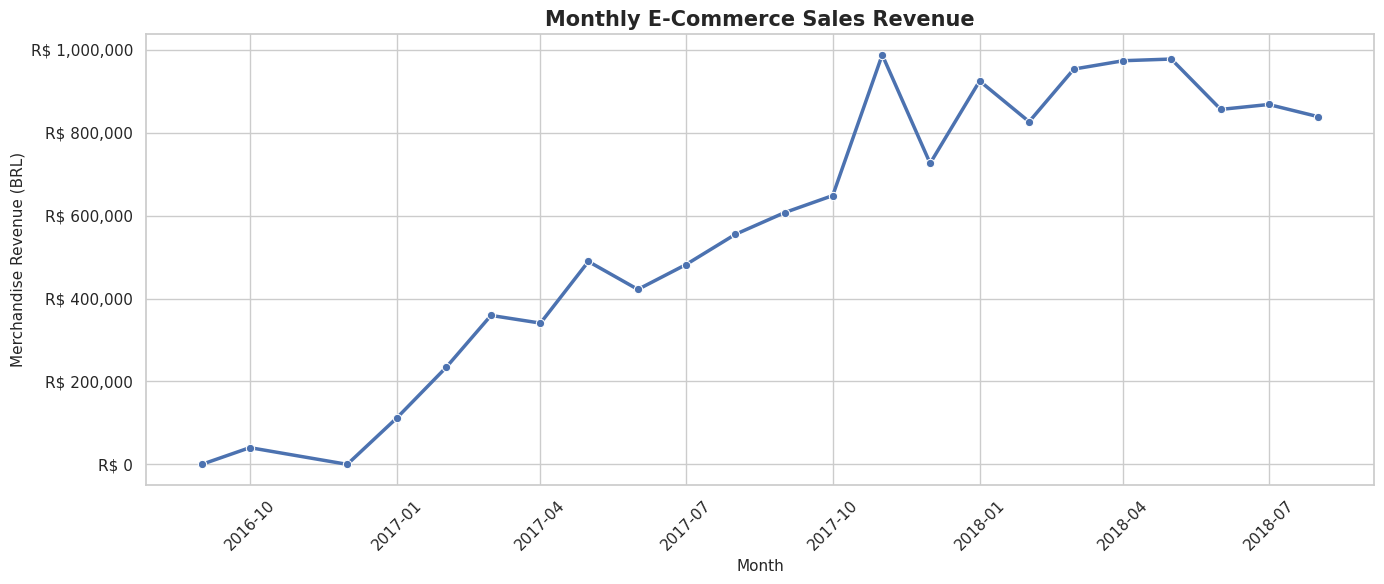

In [9]:

# ============================================================
# 8. MONTHLY SALES ANALYSIS
# ============================================================

monthly_sales = (
    analysis_df
    .groupby("order_month")
    .agg(
        total_orders=("order_id", "nunique"),
        revenue=("merchandise_revenue", "sum"),
        items_sold=("total_items", "sum")
    )
    .reset_index()
)

monthly_sales["average_order_value"] = (
    monthly_sales["revenue"] /
    monthly_sales["total_orders"]
)

display(monthly_sales.head(10))

# Visualize monthly revenue

fig, ax = plt.subplots(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="order_month",
    y="revenue",
    marker="o",
    linewidth=2.5,
    ax=ax
)

ax.set_title(
    "Monthly E-Commerce Sales Revenue",
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("Merchandise Revenue (BRL)")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"R$ {x:,.0f}")
)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


,payment_type,total_payment_value,number_of_orders
1,credit_card,12101094.88,74304
0,boleto,2769932.58,19191
3,voucher,343013.19,3679
2,debit_card,208421.12,1485


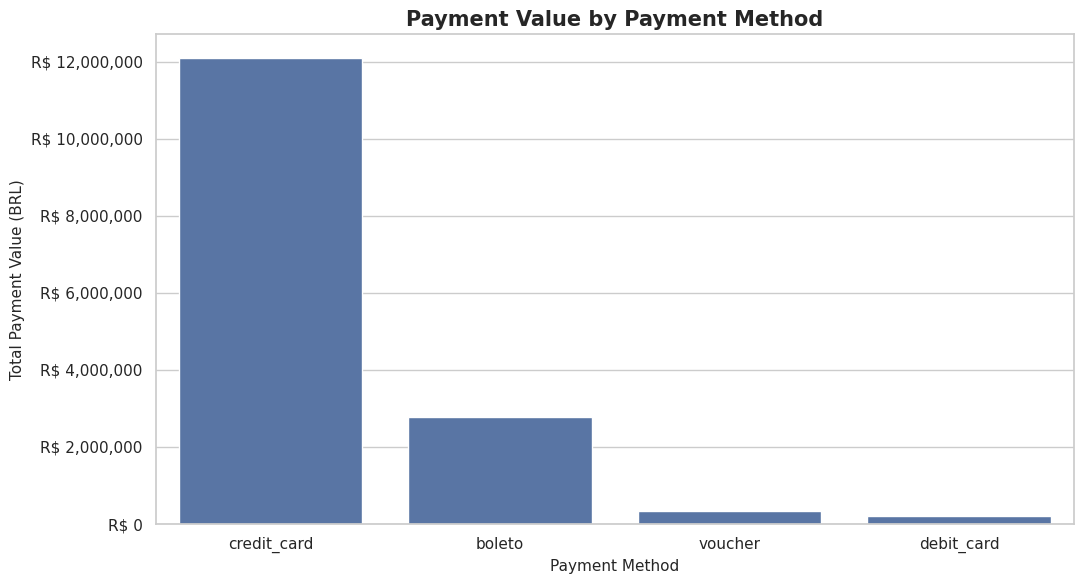

In [10]:

# ============================================================
# 9. PAYMENT METHOD ANALYSIS
# ============================================================

# Select payments belonging to delivered orders

payments_delivered = payments[
    payments["order_id"].isin(analysis_df["order_id"])
].copy()

payments_delivered["payment_type"] = (
    payments_delivered["payment_type"]
    .fillna("unknown")
)

# Aggregate by payment type

payment_summary = (
    payments_delivered
    .groupby("payment_type", as_index=False)
    .agg(
        total_payment_value=("payment_value", "sum"),
        number_of_orders=("order_id", "nunique")
    )
    .sort_values(
        "total_payment_value",
        ascending=False
    )
)

display(payment_summary)

# Visualize payment values

fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=payment_summary,
    x="payment_type",
    y="total_payment_value",
    ax=ax
)

ax.set_title(
    "Payment Value by Payment Method",
    fontweight="bold"
)

ax.set_xlabel("Payment Method")
ax.set_ylabel("Total Payment Value (BRL)")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"R$ {x:,.0f}")
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/payment_method_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


,order_status,number_of_orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


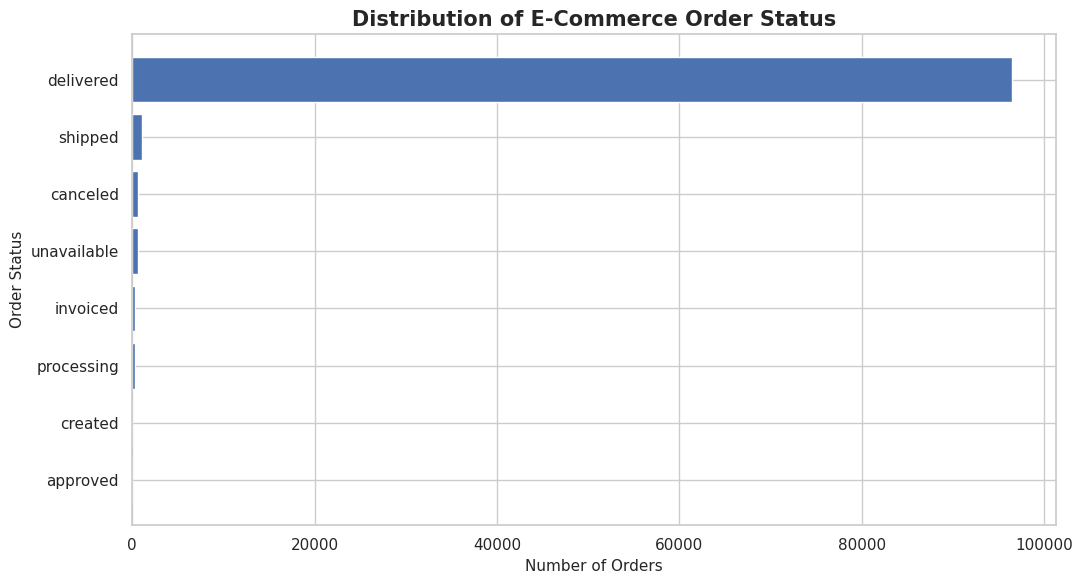

In [11]:

# ============================================================
# 10. ORDER STATUS ANALYSIS
# ============================================================

status_counts = (
    orders["order_status"]
    .value_counts()
    .rename_axis("order_status")
    .reset_index(name="number_of_orders")
)

display(status_counts)

# Visualization

status_plot = status_counts.sort_values(
    "number_of_orders"
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    status_plot["order_status"],
    status_plot["number_of_orders"]
)

ax.set_title(
    "Distribution of E-Commerce Order Status",
    fontweight="bold"
)

ax.set_xlabel("Number of Orders")
ax.set_ylabel("Order Status")

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/order_status_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


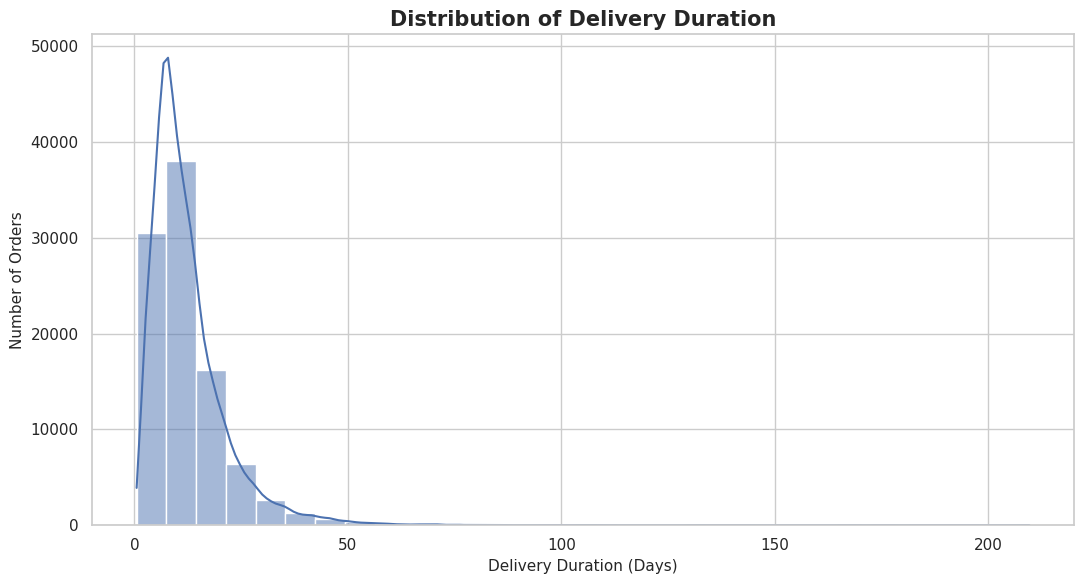

,Delivery Performance,Number of Orders
0,Late Delivery,7826
1,On Time or Early,88644


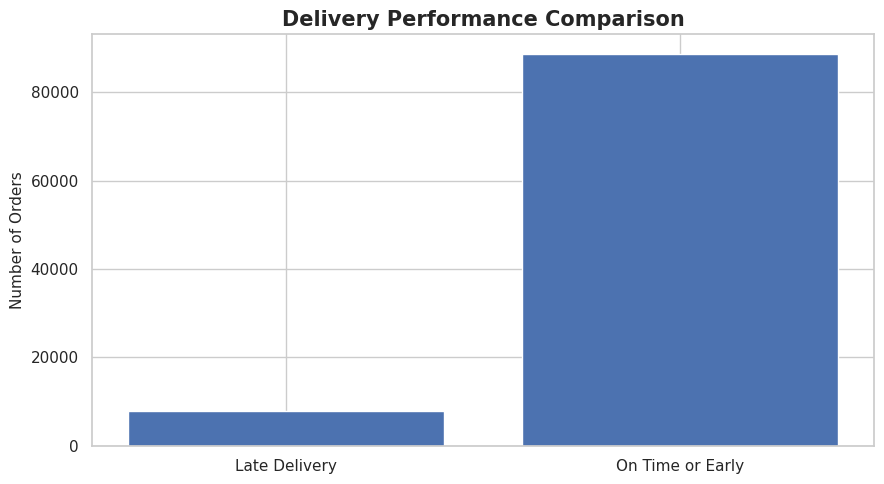

In [12]:

# ============================================================
# 11. DELIVERY PERFORMANCE ANALYSIS
# ============================================================

delivery_days = analysis_df[
    "delivery_days"
].dropna()

# Delivery duration distribution

fig, ax = plt.subplots(figsize=(11, 6))

sns.histplot(
    delivery_days,
    bins=30,
    kde=True,
    ax=ax
)

ax.set_title(
    "Distribution of Delivery Duration",
    fontweight="bold"
)

ax.set_xlabel("Delivery Duration (Days)")
ax.set_ylabel("Number of Orders")

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/delivery_duration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# On-time versus late delivery

delay_data = analysis_df[
    "delivery_delay_days"
].dropna()

late_orders = (delay_data > 0).sum()

on_time_or_early = (delay_data <= 0).sum()

delivery_summary = pd.DataFrame({
    "Delivery Performance": [
        "Late Delivery",
        "On Time or Early"
    ],
    "Number of Orders": [
        late_orders,
        on_time_or_early
    ]
})

display(delivery_summary)

# Visualize delivery performance

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    delivery_summary["Delivery Performance"],
    delivery_summary["Number of Orders"]
)

ax.set_title(
    "Delivery Performance Comparison",
    fontweight="bold"
)

ax.set_ylabel("Number of Orders")

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/delivery_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [13]:

# ============================================================
# 12. BUSINESS INSIGHTS
# ============================================================

# Best sales month

best_month = monthly_sales.loc[
    monthly_sales["revenue"].idxmax()
]

# Highest payment method by payment value

top_payment = payment_summary.iloc[0]

# Delivery metrics

average_delivery_days = (
    delivery_days.mean()
    if not delivery_days.empty else np.nan
)

late_delivery_rate = (
    (delay_data > 0).mean() * 100
    if not delay_data.empty else np.nan
)

# Print business insights

print("=" * 60)
print("BUSINESS INSIGHTS")
print("=" * 60)

print(
    f"1. Highest Sales Month: "
    f"{best_month['order_month'].strftime('%B %Y')}"
)

print(
    f"   Revenue: R$ {best_month['revenue']:,.2f}"
)

print(
    f"\n2. Highest Payment Value Method: "
    f"{top_payment['payment_type']}"
)

print(
    f"   Payment Value: "
    f"R$ {top_payment['total_payment_value']:,.2f}"
)

print(
    f"\n3. Average Delivery Duration: "
    f"{average_delivery_days:.2f} days"
)

print(
    f"\n4. Late Delivery Rate: "
    f"{late_delivery_rate:.2f}%"
)

print("=" * 60)


BUSINESS INSIGHTS
1. Highest Sales Month: November 2017
   Revenue: R$ 987,765.37

2. Highest Payment Value Method: credit_card
   Payment Value: R$ 12,101,094.88

3. Average Delivery Duration: 12.56 days

4. Late Delivery Rate: 8.11%


In [14]:

# ============================================================
# 13. EXPORT ANALYSIS RESULTS
# ============================================================

# Export cleaned dataset

analysis_df.to_csv(
    f"{OUTPUT_DIR}/cleaned_sales_data.csv",
    index=False
)

# Export analytical summaries

monthly_sales.to_csv(
    f"{OUTPUT_DIR}/monthly_sales_summary.csv",
    index=False
)

payment_summary.to_csv(
    f"{OUTPUT_DIR}/payment_summary.csv",
    index=False
)

status_counts.to_csv(
    f"{OUTPUT_DIR}/order_status_summary.csv",
    index=False
)

delivery_summary.to_csv(
    f"{OUTPUT_DIR}/delivery_summary.csv",
    index=False
)

# Create project README

readme_text = """
# Brazilian E-Commerce Sales Performance Analysis

## Project Overview

An exploratory data analysis project using Python
to examine Brazilian e-commerce sales performance.

## Dataset

Brazilian E-Commerce Public Dataset by Olist.

Source:
https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

License:
CC BY-NC-SA 4.0

## Tools

- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

## Analysis Scope

1. Data quality assessment
2. Data cleaning and preparation
3. Sales KPI analysis
4. Monthly sales trends
5. Payment method analysis
6. Order status analysis
7. Delivery performance analysis
8. Business insights

## Important Methodology Notes

- Sales KPIs use delivered orders only.
- Merchandise revenue is calculated from item prices.
- Freight is reported separately.
- Payment values are analyzed separately from merchandise revenue.
- Delivery delay is measured against the estimated delivery date.

## Limitations

This is a descriptive analysis of historical data.
The dataset covers 2016-2018 and does not represent
the current e-commerce market.

Raw dataset files are not included in this output.
Please obtain the data from the original Kaggle source
and comply with its license.
"""

with open(
    f"{OUTPUT_DIR}/README.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(readme_text)

# Package all outputs into ZIP

zip_path = shutil.make_archive(
    "/content/olist_portfolio_outputs",
    "zip",
    OUTPUT_DIR
)

print("PROJECT EXPORT COMPLETED!")
print("Output folder:", OUTPUT_DIR)
print("ZIP file:", zip_path)

print("\nFiles generated:")

for filename in os.listdir(OUTPUT_DIR):
    print("-", filename)


PROJECT EXPORT COMPLETED!
Output folder: /content/olist_portfolio_outputs
ZIP file: /content/olist_portfolio_outputs.zip

Files generated:
- delivery_performance.png
- delivery_duration.png
- order_status_analysis.png
- monthly_sales_summary.csv
- payment_method_analysis.png
- order_status_summary.csv
- README.md
- payment_summary.csv
- delivery_summary.csv
- monthly_sales_trend.png
- cleaned_sales_data.csv


In [15]:

from google.colab import files

files.download(
    "/content/olist_portfolio_outputs.zip"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>